# Calibration: recovery, weighting and identifiability

Family 21. Quote uncertainty is generated explicitly. Calibration success,
parameter identifiability and predictive performance are different questions.
Local covariance estimates are residual-scaled linear approximations.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'convexity').exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from convexity.math import contracts as ct, curves as cv, pricing as pr
rng = np.random.default_rng(2100)
ref, expiry = '2026-01-01', '2027-01-01'
discount, dividend = cv.flat_curve(ref, .04), cv.flat_curve(ref, .01)
model = pr.BlackScholesModel(100., discount, dividend, .2)
plt.rcParams.update({'figure.figsize': (9, 3.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})
print('Interpreter:', sys.executable)

Interpreter: /home/ethan/miniconda3/envs/quant/bin/python


## Recover volatility with heteroskedastic quote noise

The precision weights match the generated observation noise. The reported
covariance estimates residual scale; it is not a Bayesian posterior.

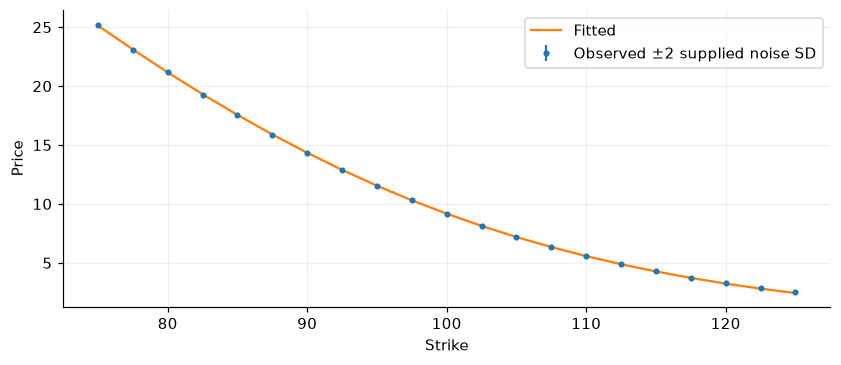

,Truth,Estimate,Local standard error,RMSE
0,0.24,0.239839,0.000182,0.040583


In [2]:
from convexity.math import calibration as ca
strikes=np.linspace(75,125,21)
def predict(p):
    return np.array([pr.forward_option(100.,s,p[0],1.,discount=np.exp(-.04)) for s in strikes])
truth=predict([.24]);noise=.015+.0015*np.abs(strikes-100)
observed=truth+rng.normal(size=len(strikes))*noise
fit=ca.calibrate(ca.CalibrationProblem(predict,observed,[.4],weights=1/noise**2,lower=[.01],upper=[1.]))
plt.errorbar(strikes,observed,yerr=2*noise,fmt='.',label='Observed ±2 supplied noise SD')
plt.plot(strikes,predict(fit.parameters),label='Fitted');plt.xlabel('Strike');plt.ylabel('Price');plt.legend();plt.show()
display(pd.DataFrame({'Truth':[.24],'Estimate':fit.parameters,'Local standard error':np.sqrt(np.diag(fit.covariance)),'RMSE':[fit.rmse]}))

## A flat direction can remain after convergence

This deliberately redundant parameterization identifies only the sum of two
parameters. A small residual does not identify either component. Singular values
and absent covariance reveal the problem.

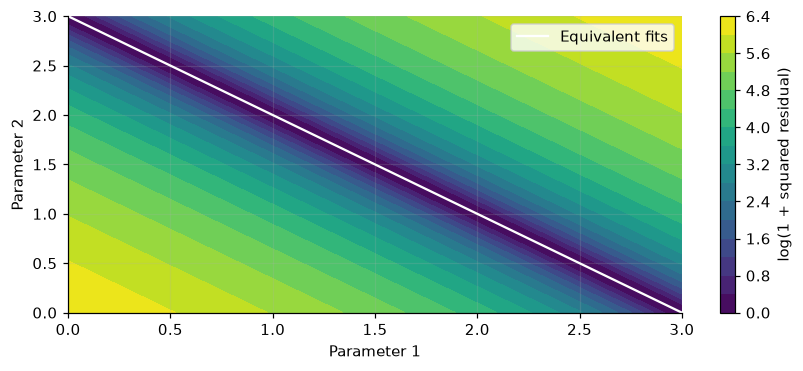

,parameter
0,0.630599
1,2.369401


Rank: 1 Singular values: [1.14642301e+01 1.03164596e-10] Covariance: None


In [3]:
x=np.linspace(1,3,15)
redundant=lambda p:(p[0]+p[1])*x
result=ca.calibrate(ca.CalibrationProblem(redundant,3*x,[1.,1.]))
a=np.linspace(0,3,100);b=np.linspace(0,3,100);A,B=np.meshgrid(a,b)
loss=np.sum(x*x)*(A+B-3)**2
plt.contourf(A,B,np.log1p(loss),levels=20);plt.colorbar(label='log(1 + squared residual)')
plt.plot(a,3-a,color='white',label='Equivalent fits');plt.xlabel('Parameter 1');plt.ylabel('Parameter 2');plt.legend();plt.show()
display(pd.DataFrame({'parameter':result.parameters}));print('Rank:',result.rank,'Singular values:',result.singular_values,'Covariance:',result.covariance)

## Bounds and regularization change the inverse problem

A bound can prevent recovery despite a converged optimizer. Regularization
selects a solution relative to a supplied prior. Neither case receives an
unconstrained residual-based covariance.

,fit,parameters,RMSE,covariance available
0,Unrestricted volatility,[0.23983925849754464],0.040583,True
1,Volatility capped at .20,[0.19999999999999998],1.254544,False
2,Regularized redundant model,"[1.3939393938087528, 1.3939393938087525]",0.443985,False


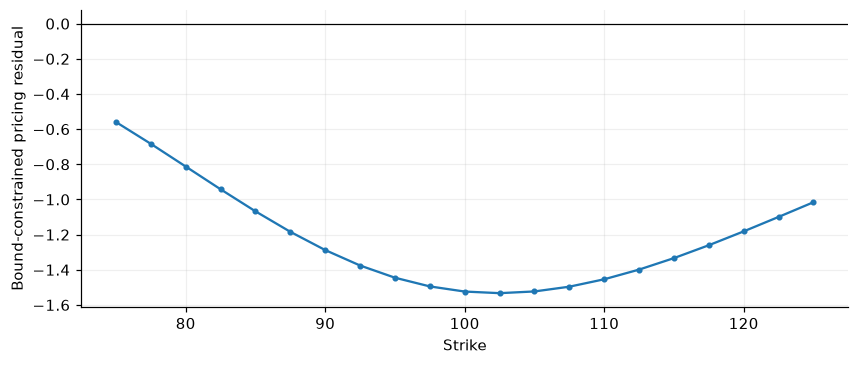

In [4]:
bounded=ca.calibrate(ca.CalibrationProblem(predict,truth,[.15],lower=[.01],upper=[.2]))
penalized=ca.calibrate(ca.CalibrationProblem(redundant,3*x,[1.,1.],prior=[0.,0.],regularization=10.))
display(pd.DataFrame({'fit':['Unrestricted volatility','Volatility capped at .20','Regularized redundant model'],
 'parameters':[fit.parameters.tolist(),bounded.parameters.tolist(),penalized.parameters.tolist()],
 'RMSE':[fit.rmse,bounded.rmse,penalized.rmse],
 'covariance available':[fit.covariance is not None,bounded.covariance is not None,penalized.covariance is not None]}))
plt.plot(strikes,predict(bounded.parameters)-truth,marker='.');plt.axhline(0,color='black',lw=.8);plt.xlabel('Strike');plt.ylabel('Bound-constrained pricing residual');plt.show()

## Scope of the evidence

These are generated-data experiments under the stated models, not market forecasts or universal model rankings. Numerical errors, backend restrictions and measure assumptions are documented in the [financial catalog](../docs/financial_mathematics.md) and [QA record](../docs/financial_qa.md). Automated adversarial checks live in `tests/math/finance/`.